# Assignment 3: Eyes on the Road (Part II + Part III)

Student ID: 315511079

Run on Google Colab with a GPU runtime. Part II uses NumPy only (CPU); Part III uses PyTorch.
`sample_submission.csv` and `validation_ids.csv` from the class Kaggle competition must be uploaded
to the working directory before running. The notebook writes the two Kaggle submissions
(`part2/submission.csv`, `part3/submission.csv`), all figures, tables and a results summary.

In [1]:
%%writefile nn_numpy.py
"""Assignment 3, Part II: a small neural-network library written with NumPy only."""
import numpy as np

def affine_forward(X, W, b):
    """Z = XW + b.   X: (N, D), W: (D, M), b: (M,)  ->  Z: (N, M)"""
    Z = X @ W + b
    cache = (X, W)
    return Z, cache

def affine_backward(dZ, cache):
    """Returns dX (N, D), dW (D, M), db (M,)."""
    X, W = cache
    dX = dZ @ W.T
    dW = X.T @ dZ
    db = dZ.sum(axis=0)
    return dX, dW, db

def relu_forward(Z):
    A = np.maximum(0, Z)
    cache = Z
    return A, cache

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0)

def sigmoid_forward(Z):
    # numerically stable sigmoid
    A = np.exp(-np.logaddexp(0, -Z)).astype(Z.dtype, copy=False)
    cache = A
    return A, cache

def sigmoid_backward(dA, cache):
    A = cache
    return dA * A * (1 - A)

def softmax_ce_loss(S, y):
    """S: scores (N, C), y: integer labels (N,)."""
    N = S.shape[0]
    shifted = S - S.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    loss = -log_probs[np.arange(N), y].mean()
    dS = np.exp(log_probs)
    dS[np.arange(N), y] -= 1
    dS /= N
    return loss, dS

def hinge_loss(S, y, delta=1.0):
    """Multiclass hinge loss: sum_{j != y} max(0, s_j - s_y + delta), averaged."""
    N = S.shape[0]
    correct = S[np.arange(N), y][:, None]
    margins = np.maximum(0, S - correct + delta)
    margins[np.arange(N), y] = 0
    loss = margins.sum() / N
    mask = (margins > 0).astype(S.dtype)
    mask[np.arange(N), y] = -mask.sum(axis=1)
    dS = mask / N
    return loss, dS

LOSSES = {"softmax": softmax_ce_loss, "hinge": hinge_loss}
ACTIVATIONS = {
    "relu": (relu_forward, relu_backward),
    "sigmoid": (sigmoid_forward, sigmoid_backward),
}

def numerical_gradient(f, x, h=1e-5):
    """Centered finite differences of the scalar function f at x.
    x is modified in place during the computation and restored afterwards."""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"], op_flags=["readwrite"])
    while not it.finished:
        i = it.multi_index
        old = x[i]
        x[i] = old + h
        fp = f(x)
        x[i] = old - h
        fm = f(x)
        x[i] = old
        grad[i] = (fp - fm) / (2 * h)
        it.iternext()
    return grad

def rel_error(a, n):
    """max_i |a_i - n_i| / max(1e-8, |a_i| + |n_i|)"""
    return np.max(np.abs(a - n) / np.maximum(1e-8, np.abs(a) + np.abs(n)))

class MLP:
    def __init__(self, input_dim, hidden_dims, num_classes=10, activation="relu",
                 init="he", std=1e-2, reg=0.0, loss="softmax",
                 dtype=np.float32, seed=0):
        """
        init: 'zero' | 'gaussian' (uses std) | 'he' (std = sqrt(2 / fan_in))
        reg : L2 strength; penalty = 0.5 * reg * sum(W**2) over all weight matrices
        """
        rng = np.random.default_rng(seed)
        self.act_f, self.act_b = ACTIVATIONS[activation]
        self.loss_fn = LOSSES[loss]
        self.reg = reg
        self.dtype = dtype
        dims = [input_dim] + list(hidden_dims) + [num_classes]
        self.L = len(dims) - 1
        self.params = {}
        for l in range(1, self.L + 1):
            fan_in, fan_out = dims[l - 1], dims[l]
            if init == "zero":
                W = np.zeros((fan_in, fan_out))
            elif init == "gaussian":
                W = std * rng.standard_normal((fan_in, fan_out))
            elif init == "he":
                W = np.sqrt(2.0 / fan_in) * rng.standard_normal((fan_in, fan_out))
            else:
                raise ValueError(init)
            self.params[f"W{l}"] = W.astype(dtype)
            self.params[f"b{l}"] = np.zeros(fan_out, dtype=dtype)

    def scores(self, X):
        A = X.astype(self.dtype, copy=False)
        for l in range(1, self.L):
            A, _ = affine_forward(A, self.params[f"W{l}"], self.params[f"b{l}"])
            A, _ = self.act_f(A)
        S, _ = affine_forward(A, self.params[f"W{self.L}"], self.params[f"b{self.L}"])
        return S

    def loss(self, X, y):
        """Returns (loss, grads)."""
        A = X.astype(self.dtype, copy=False)
        caches = []
        for l in range(1, self.L):
            A, c_aff = affine_forward(A, self.params[f"W{l}"], self.params[f"b{l}"])
            A, c_act = self.act_f(A)
            caches.append((c_aff, c_act))
        S, c_last = affine_forward(A, self.params[f"W{self.L}"], self.params[f"b{self.L}"])

        data_loss, dS = self.loss_fn(S, y)
        reg_loss = 0.5 * self.reg * sum(np.sum(self.params[f"W{l}"] ** 2)
                                        for l in range(1, self.L + 1))
        grads = {}
        dA, grads[f"W{self.L}"], grads[f"b{self.L}"] = affine_backward(dS, c_last)
        for l in range(self.L - 1, 0, -1):
            c_aff, c_act = caches[l - 1]
            dZ = self.act_b(dA, c_act)
            dA, grads[f"W{l}"], grads[f"b{l}"] = affine_backward(dZ, c_aff)
        for l in range(1, self.L + 1):
            grads[f"W{l}"] = grads[f"W{l}"] + self.reg * self.params[f"W{l}"]
        return data_loss + reg_loss, grads

    def predict(self, X, batch_size=2000):
        return np.concatenate([self.scores(X[i:i + batch_size]).argmax(1)
                               for i in range(0, len(X), batch_size)])

    def accuracy(self, X, y):
        return float((self.predict(X) == y).mean())

    def eval_loss(self, X, y, batch_size=2000):
        """Data loss (no regularization) on a whole set."""
        tot = 0.0
        for i in range(0, len(X), batch_size):
            l, _ = self.loss_fn(self.scores(X[i:i + batch_size]), y[i:i + batch_size])
            tot += l * len(X[i:i + batch_size])
        return tot / len(X)

def train(model, X, y, X_val, y_val, lr=1e-3, epochs=10, batch_size=200,
          momentum=0.0, lr_decay=1.0, seed=0, verbose=True, n_train_eval=5000):
    """Plain SGD when momentum = 0.  lr is multiplied by lr_decay after each epoch.
    Returns a history dict with per-epoch train/val loss and accuracy."""
    rng = np.random.default_rng(seed)
    N = X.shape[0]
    vel = {k: np.zeros_like(p) for k, p in model.params.items()}
    sub = rng.choice(N, min(n_train_eval, N), replace=False)
    hist = {"iter_loss": [], "train_loss": [], "val_loss": [],
            "train_acc": [], "val_acc": [], "diverged": False}
    with np.errstate(over="ignore", invalid="ignore"):
        for ep in range(epochs):
            perm = rng.permutation(N)
            ep_losses = []
            for i in range(0, N, batch_size):
                idx = perm[i:i + batch_size]
                loss, grads = model.loss(X[idx], y[idx])
                if not np.isfinite(loss):
                    hist["diverged"] = True
                    break
                for k in model.params:
                    vel[k] = momentum * vel[k] - lr * grads[k]
                    model.params[k] += vel[k]
                ep_losses.append(float(loss))
            hist["iter_loss"] += ep_losses
            if hist["diverged"]:
                if verbose:
                    print(f"epoch {ep + 1}: loss became NaN/inf -> diverged, stopping")
                break
            lr *= lr_decay
            hist["train_loss"].append(float(np.mean(ep_losses)))
            hist["val_loss"].append(model.eval_loss(X_val, y_val))
            hist["train_acc"].append(model.accuracy(X[sub], y[sub]))
            hist["val_acc"].append(model.accuracy(X_val, y_val))
            if verbose:
                print(f"epoch {ep + 1:2d}/{epochs}  train loss {hist['train_loss'][-1]:.4f}  "
                      f"train acc {hist['train_acc'][-1]:.4f}  val acc {hist['val_acc'][-1]:.4f}")
    return hist

Writing nn_numpy.py


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, random
import torchvision
import importlib, nn_numpy
importlib.reload(nn_numpy)
from nn_numpy import *

random.seed(0); np.random.seed(0)

import os, re
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
for d in ["figures", "tables", "part2", "part3"]:
    os.makedirs(os.path.join(OUT, d), exist_ok=True)
_fig_count = [0]
_plt_show = plt.show
def _show_and_save(*args, **kwargs):
    """Every figure shown is also saved to figures/ for the PDF report."""
    fig = plt.gcf()
    title = fig.axes[0].get_title() if fig.axes else ""
    name = re.sub(r"[^A-Za-z0-9]+", "_", title).strip("_")[:50] or "figure"
    _fig_count[0] += 1
    fig.savefig(os.path.join(OUT, "figures", f"{_fig_count[0]:02d}_{name}.png"), dpi=150, bbox_inches="tight")
    _plt_show(*args, **kwargs)
plt.show = _show_and_save

## 1. Data: CIFAR-10
Scale to [0, 1], flatten to 3072, hold out the **last 5,000** training images as validation,
and subtract the mean image of the **45,000** training images only.

In [3]:
train_set = torchvision.datasets.CIFAR10("./data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True)

X_all = train_set.data.reshape(len(train_set.data), -1).astype(np.float32) / 255.0
y_all = np.array(train_set.targets)
X_test = test_set.data.reshape(len(test_set.data), -1).astype(np.float32) / 255.0
y_test = np.array(test_set.targets)

X_train, y_train = X_all[:45000], y_all[:45000]
X_val, y_val = X_all[45000:], y_all[45000:]
mean_image = X_train.mean(axis=0)
X_train = X_train - mean_image
X_val = X_val - mean_image
X_test = X_test - mean_image
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)

100%|██████████| 170M/170M [31:54<00:00, 89.0kB/s]


train (45000, 3072) val (5000, 3072) test (10000, 3072)


## (a) Gradient check
Every layer and both losses are checked in float64 with centered differences ($h=10^{-5}$).
For a layer with output $Z$ we check the scalar $f = \sum Z \odot G$ for a random upstream gradient $G$.

In [4]:
rng = np.random.default_rng(0)
rows = []
N, D, H, C = 6, 8, 7, 5
X = rng.standard_normal((N, D)); W = rng.standard_normal((D, H)); b = rng.standard_normal(H)
G = rng.standard_normal((N, H))

_, cache = affine_forward(X, W, b)
dX, dW, db = affine_backward(G, cache)
rows += [("affine", "dX", rel_error(dX, numerical_gradient(lambda x: np.sum(affine_forward(x, W, b)[0] * G), X.copy()))),
         ("affine", "dW", rel_error(dW, numerical_gradient(lambda w: np.sum(affine_forward(X, w, b)[0] * G), W.copy()))),
         ("affine", "db", rel_error(db, numerical_gradient(lambda v: np.sum(affine_forward(X, W, v)[0] * G), b.copy())))]

Z = rng.standard_normal((N, H))
for name, (fwd, bwd) in ACTIVATIONS.items():
    _, cache = fwd(Z)
    rows.append((name, "dZ", rel_error(bwd(G, cache),
                 numerical_gradient(lambda z: np.sum(fwd(z)[0] * G), Z.copy()))))

S = rng.standard_normal((N, C)); y = rng.integers(0, C, N)
for name, fn in LOSSES.items():
    rows.append((name + " loss", "dS", rel_error(fn(S, y)[1],
                 numerical_gradient(lambda s: fn(s, y)[0], S.copy()))))

Xs = rng.standard_normal((N, D)); ys = rng.integers(0, C, N)
for act in ["relu", "sigmoid"]:
    for loss in ["softmax", "hinge"]:
        net = MLP(D, [7, 6], C, activation=act, init="gaussian", std=0.5,
                  reg=0.1, loss=loss, dtype=np.float64, seed=0)
        _, grads = net.loss(Xs, ys)
        for k in net.params:
            def f(p, k=k):
                old = net.params[k]; net.params[k] = p
                val = net.loss(Xs, ys)[0]; net.params[k] = old
                return val
            rows.append((f"net[{act}, {loss}]", k,
                         rel_error(grads[k], numerical_gradient(f, net.params[k].copy()))))

grad_table = pd.DataFrame(rows, columns=["component", "gradient", "relative error"])
pd.set_option("display.max_rows", 100)
display(grad_table.style.format({"relative error": "{:.2e}"}))
print("all below 1e-6:", bool((grad_table["relative error"] < 1e-6).all()))

,component,gradient,relative error
0,affine,dX,5.71e-10
1,affine,dW,3.93e-10
2,affine,db,5.65e-10
3,relu,dZ,6.50e-11
4,sigmoid,dZ,1.44e-09
5,softmax loss,dS,2.36e-09
6,hinge loss,dS,6.99e-11
7,"net[relu, softmax]",W1,4.32e-09
8,"net[relu, softmax]",b1,1.14e-08
9,"net[relu, softmax]",W2,2.32e-09


all below 1e-6: True


## (b) Training
### Sanity check: overfit 50 images
A correct implementation should reach ~100% training accuracy on a tiny subset with no regularization.

final loss 0.0372, training accuracy on the 50 images: 1.00


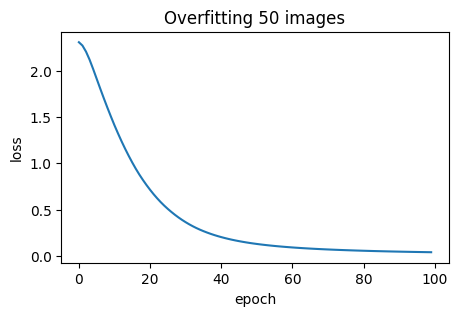

In [5]:
X50, y50 = X_train[:50], y_train[:50]
net = MLP(3072, [100], 10, init="he", reg=0.0, seed=0)
h50 = train(net, X50, y50, X50, y50, lr=1e-2, momentum=0.9, epochs=100,
            batch_size=50, verbose=False)
print(f"final loss {h50['train_loss'][-1]:.4f}, training accuracy on the 50 images: {h50['train_acc'][-1]:.2f}")
plt.figure(figsize=(5, 3)); plt.plot(h50["train_loss"]); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Overfitting 50 images"); plt.show()

### TA baseline
100 hidden units, $W\sim\mathcal N(0,10^{-4})$ (std $10^{-2}$), zero biases, no regularization, softmax,
plain SGD, learning rate $10^{-3}$, batch 200, 10 epochs.

In [6]:
t0 = time.time()
base = MLP(3072, [100], 10, init="gaussian", std=1e-2, reg=0.0, loss="softmax", seed=0)
h_base = train(base, X_train, y_train, X_val, y_val, lr=1e-3, epochs=10, batch_size=200)
print(f"baseline val acc = {h_base['val_acc'][-1]:.4f}   ({time.time() - t0:.0f}s)")

epoch  1/10  train loss 2.3018  train acc 0.1326  val acc 0.1358
epoch  2/10  train loss 2.3003  train acc 0.1516  val acc 0.1594
epoch  3/10  train loss 2.2988  train acc 0.1760  val acc 0.1784
epoch  4/10  train loss 2.2971  train acc 0.1956  val acc 0.2004
epoch  5/10  train loss 2.2952  train acc 0.2100  val acc 0.2134
epoch  6/10  train loss 2.2931  train acc 0.2132  val acc 0.2184
epoch  7/10  train loss 2.2907  train acc 0.2210  val acc 0.2192
epoch  8/10  train loss 2.2878  train acc 0.2238  val acc 0.2178
epoch  9/10  train loss 2.2844  train acc 0.2228  val acc 0.2176
epoch 10/10  train loss 2.2805  train acc 0.2210  val acc 0.2166
baseline val acc = 0.2166   (11s)


### Hyperparameter search (validation set only)
All runs: He initialization, SGD with momentum 0.9, batch 200, learning rate × 0.95 per epoch, 20 epochs.

In [7]:
configs = [  # (hidden size, learning rate, L2 strength)
    (100, 1e-2, 1e-3),
    (200, 1e-2, 1e-3),
    (500, 1e-2, 1e-3),
    (500, 2e-3, 1e-3),
    (500, 5e-2, 1e-3),
    (500, 1e-2, 1e-2),
]
EPOCHS = 20
results, histories = [], {}
for hid, lr, reg in configs:
    t0 = time.time()
    net = MLP(3072, [hid], 10, init="he", reg=reg, loss="softmax", seed=0)
    h = train(net, X_train, y_train, X_val, y_val, lr=lr, momentum=0.9,
              lr_decay=0.95, epochs=EPOCHS, batch_size=200, verbose=False)
    histories[(hid, lr, reg)] = (net, h)
    best_val = max(h["val_acc"]) if h["val_acc"] else float("nan")
    results.append({"hidden": hid, "lr": lr, "reg": reg,
                    "train acc": h["train_acc"][-1] if h["train_acc"] else np.nan,
                    "final val acc": h["val_acc"][-1] if h["val_acc"] else np.nan,
                    "best val acc": best_val, "time (s)": round(time.time() - t0)})
    print(results[-1])

res_df = pd.DataFrame(results)
display(res_df.style.format({"lr": "{:g}", "reg": "{:g}", "train acc": "{:.4f}",
                             "final val acc": "{:.4f}", "best val acc": "{:.4f}"}))

best_cfg = tuple(res_df.sort_values("final val acc", ascending=False).iloc[0][["hidden", "lr", "reg"]])
best_cfg = (int(best_cfg[0]), float(best_cfg[1]), float(best_cfg[2]))
best_net, best_hist = histories[best_cfg]
print("best config (hidden, lr, reg):", best_cfg,
      f"val acc {best_hist['val_acc'][-1]:.4f} vs baseline {h_base['val_acc'][-1]:.4f}")

{'hidden': 100, 'lr': 0.01, 'reg': 0.001, 'train acc': 0.61, 'final val acc': 0.5264, 'best val acc': 0.5304, 'time (s)': 19}
{'hidden': 200, 'lr': 0.01, 'reg': 0.001, 'train acc': 0.6302, 'final val acc': 0.5438, 'best val acc': 0.5438, 'time (s)': 34}
{'hidden': 500, 'lr': 0.01, 'reg': 0.001, 'train acc': 0.6716, 'final val acc': 0.5538, 'best val acc': 0.5538, 'time (s)': 72}
{'hidden': 500, 'lr': 0.002, 'reg': 0.001, 'train acc': 0.5184, 'final val acc': 0.4846, 'best val acc': 0.4852, 'time (s)': 70}
{'hidden': 500, 'lr': 0.05, 'reg': 0.001, 'train acc': 0.8144, 'final val acc': 0.5546, 'best val acc': 0.5608, 'time (s)': 73}
{'hidden': 500, 'lr': 0.01, 'reg': 0.01, 'train acc': 0.5388, 'final val acc': 0.504, 'best val acc': 0.5064, 'time (s)': 72}


,hidden,lr,reg,train acc,final val acc,best val acc,time (s)
0,100,0.01,0.001,0.6100,0.5264,0.5304,19
1,200,0.01,0.001,0.6302,0.5438,0.5438,34
2,500,0.01,0.001,0.6716,0.5538,0.5538,72
3,500,0.002,0.001,0.5184,0.4846,0.4852,70
4,500,0.05,0.001,0.8144,0.5546,0.5608,73
5,500,0.01,0.01,0.5388,0.5040,0.5064,72


best config (hidden, lr, reg): (500, 0.05, 0.001) val acc 0.5546 vs baseline 0.2166


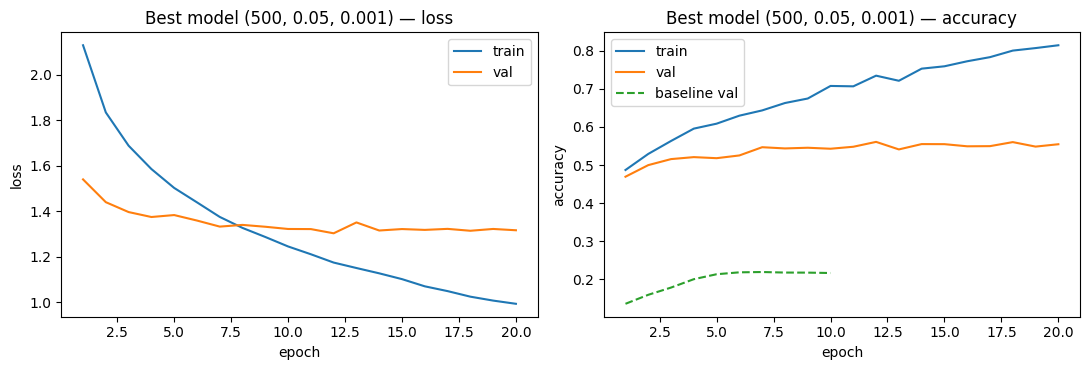

In [8]:
def plot_curves(h, title, h_ref=None, ref_name="baseline"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="val")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title(title + " — loss"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="train"); ax[1].plot(ep, h["val_acc"], label="val")
    if h_ref is not None:
        ax[1].plot(np.arange(1, len(h_ref["val_acc"]) + 1), h_ref["val_acc"], "--", label=f"{ref_name} val")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title(title + " — accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_curves(best_hist, f"Best model {best_cfg}", h_base)

### Softmax vs hinge loss
Same architecture and hyperparameters as the best model; only the output loss changes.

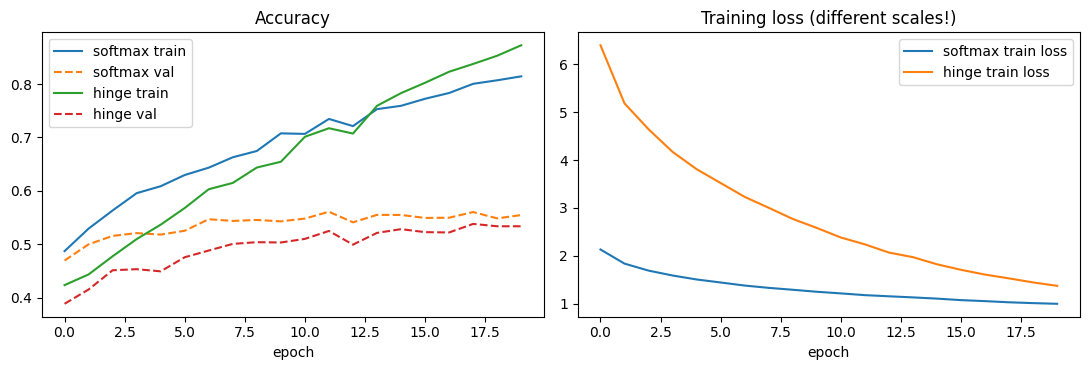

val acc  softmax 0.5546   hinge 0.5336


In [9]:
hid, lr, reg = best_cfg
net_hinge = MLP(3072, [hid], 10, init="he", reg=reg, loss="hinge", seed=0)
h_hinge = train(net_hinge, X_train, y_train, X_val, y_val, lr=lr, momentum=0.9,
                lr_decay=0.95, epochs=EPOCHS, batch_size=200, verbose=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, h in [("softmax", best_hist), ("hinge", h_hinge)]:
    ax[0].plot(h["train_acc"], label=f"{name} train"); ax[0].plot(h["val_acc"], "--", label=f"{name} val")
    ax[1].plot(h["train_loss"], label=f"{name} train loss")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Training loss (different scales!)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"val acc  softmax {best_hist['val_acc'][-1]:.4f}   hinge {h_hinge['val_acc'][-1]:.4f}")

## (c) Design issues — five hidden layers (100 units each)
### (i) Initialization  and  (ii) sigmoid vs ReLU
Mean absolute gradient of each layer's weights is measured on the **first mini-batch, before any update**.
Each network is then trained for 5 epochs (SGD + momentum 0.9, lr $10^{-2}$, batch 200, no L2).

In [10]:
DEEP = [100] * 5
Xb, yb = X_train[:200], y_train[:200]

def layer_grads(net):
    with np.errstate(over="ignore", invalid="ignore"):
        _, g = net.loss(Xb, yb)
    return [float(np.mean(np.abs(g[f"W{l}"]))) for l in range(1, net.L + 1)]

init_settings = {"zero": dict(init="zero"),
                 "small (std=1e-2)": dict(init="gaussian", std=1e-2),
                 "large (std=1)": dict(init="gaussian", std=1.0),
                 "He": dict(init="he")}

grad_rows, init_hist = {}, {}
for name, kw in init_settings.items():
    net = MLP(3072, DEEP, 10, activation="relu", seed=0, **kw)
    grad_rows[name] = layer_grads(net)
    init_hist[name] = train(net, X_train, y_train, X_val, y_val, lr=1e-2, momentum=0.9,
                            epochs=5, batch_size=200, verbose=False)

act_hist = {}
for act in ["relu", "sigmoid"]:
    net = MLP(3072, DEEP, 10, activation=act, init="he", seed=0)
    grad_rows[f"{act} (He init)"] = layer_grads(net)
    act_hist[act] = train(net, X_train, y_train, X_val, y_val, lr=1e-2, momentum=0.9,
                          epochs=5, batch_size=200, verbose=False)

grad_df = pd.DataFrame(grad_rows, index=[f"W{l}" for l in range(1, 7)]).T
display(grad_df.style.format("{:.2e}"))

,W1,W2,W3,W4,W5,W6
zero,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
small (std=1e-2),2.40e-09,1.17e-08,1.03e-08,9.43e-09,9.76e-09,3.11e-08
large (std=1),6.61e+01,6.95e+02,6.65e+02,7.01e+02,7.36e+02,2.02e+03
He,1.40e-03,1.42e-03,1.34e-03,1.33e-03,1.33e-03,4.62e-03
relu (He init),1.40e-03,1.42e-03,1.34e-03,1.33e-03,1.33e-03,4.62e-03
sigmoid (He init),5.57e-06,9.12e-05,2.83e-04,1.02e-03,3.13e-03,2.40e-02


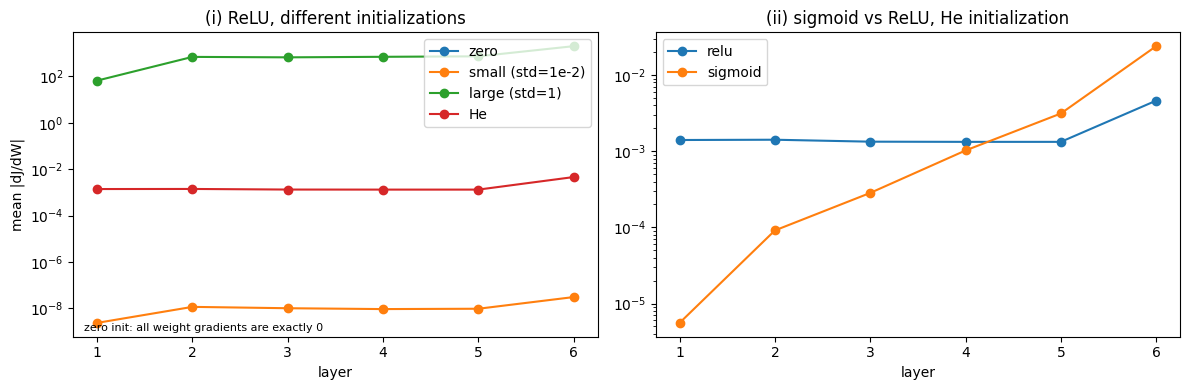

,diverged,final train loss,final val acc
zero,False,2.302763,0.0986
small (std=1e-2),False,2.302763,0.0986
large (std=1),True,NaN,NaN
He,False,1.305701,0.4878


,diverged,final train loss,final val acc
relu,False,1.305701,0.4878
sigmoid,False,2.303054,0.095


In [11]:
layers = np.arange(1, 7)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in init_settings:
    v = np.array(grad_rows[name]); v = np.where(v > 0, v, np.nan)   # zeros cannot be drawn on a log axis
    ax[0].semilogy(layers, v, "o-", label=name)
ax[0].set_title("(i) ReLU, different initializations"); ax[0].set_xlabel("layer"); ax[0].set_ylabel("mean |dJ/dW|")
ax[0].set_xticks(layers); ax[0].legend()
ax[0].text(0.02, 0.02, "zero init: all weight gradients are exactly 0", transform=ax[0].transAxes, fontsize=8)
for act in ["relu", "sigmoid"]:
    ax[1].semilogy(layers, grad_rows[f"{act} (He init)"], "o-", label=act)
ax[1].set_title("(ii) sigmoid vs ReLU, He initialization"); ax[1].set_xlabel("layer"); ax[1].set_xticks(layers)
ax[1].legend(); plt.tight_layout(); plt.show()

def summarise(hd):
    return pd.DataFrame({k: {"diverged": h["diverged"],
                             "final train loss": h["train_loss"][-1] if h["train_loss"] else np.nan,
                             "final val acc": h["val_acc"][-1] if h["val_acc"] else np.nan}
                         for k, h in hd.items()}).T
display(summarise(init_hist)); display(summarise(act_hist))

### (iii) L2 regularization strength
To make overfitting visible we train on a 5,000-image subset for 40 epochs (ReLU, He, lr $10^{-2}$, momentum 0.9)
and evaluate on the full validation set.

,reg,train acc,val acc,gap
0,0,0.9880,0.3776,0.6104
1,0.001,0.9920,0.3966,0.5954
2,0.01,0.8940,0.3976,0.4964
3,0.1,0.1038,0.0976,0.0062


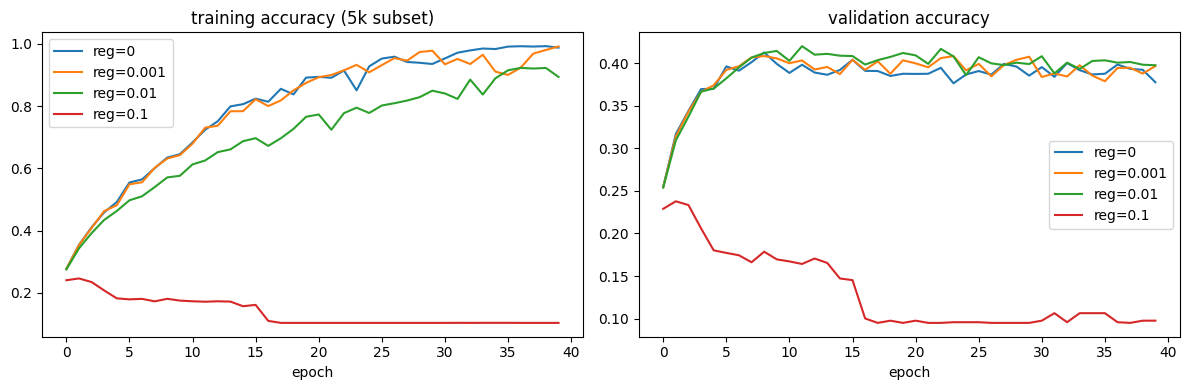

In [12]:
Xsub, ysub = X_train[:5000], y_train[:5000]
regs = [0.0, 1e-3, 1e-2, 1e-1]
reg_hist, reg_rows = {}, []
for r in regs:
    net = MLP(3072, DEEP, 10, activation="relu", init="he", reg=r, seed=0)
    h = train(net, Xsub, ysub, X_val, y_val, lr=1e-2, momentum=0.9, epochs=40,
              batch_size=200, verbose=False)
    reg_hist[r] = h
    reg_rows.append({"reg": r, "train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1],
                     "gap": h["train_acc"][-1] - h["val_acc"][-1]})
display(pd.DataFrame(reg_rows).style.format({"reg": "{:g}", "train acc": "{:.4f}",
                                             "val acc": "{:.4f}", "gap": "{:.4f}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r, h in reg_hist.items():
    ax[0].plot(h["train_acc"], label=f"reg={r:g}")
    ax[1].plot(h["val_acc"], label=f"reg={r:g}")
ax[0].set_title("training accuracy (5k subset)"); ax[1].set_title("validation accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## Test set (evaluated once, best Part II model)
Keep this number for the comparison in Part III (d).

In [13]:
part2_test_acc = best_net.accuracy(X_test, y_test)
print(f"Part II best model {best_cfg}: test accuracy = {part2_test_acc:.4f}")

Part II best model (500, 0.05, 0.001): test accuracy = 0.5510


## Kaggle submission (validation set)
The leaderboard uses the 5,000 validation images. The competition's `validation_ids.csv` maps each
submission ID to its torchvision CIFAR-10 training index, so predictions are matched by ID, not by position.
`build_submission` is reused by Part III. (Requires **Add Input → the class competition**.)

In [15]:
import glob

def _find_input(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(name)
    return hits[0] if hits else None

def build_submission(val_preds, path):
    """val_preds[i] is the predicted class of torchvision training image 45000 + i."""
    sample_p, ids_p = _find_input("sample_submission.csv"), _find_input("validation_ids.csv")
    if sample_p is None or ids_p is None:
        raise FileNotFoundError("upload sample_submission.csv and validation_ids.csv first")
    sub = pd.read_csv(sample_p)
    id_col, label_col = sub.columns[0], sub.columns[-1]
    pred_by_index = {45000 + i: int(p) for i, p in enumerate(val_preds)}
    m = pd.read_csv(ids_p)
    sid_col = "id" if "id" in m.columns else m.columns[0]
    idx_col = "cifar10_train_index" if "cifar10_train_index" in m.columns else m.columns[-1]
    idx = m[idx_col].astype(int)
    if idx.max() < 45000:
        idx = idx + 45000
    to_index = dict(zip(m[sid_col].astype(str), idx))
    sub_ids = sub[id_col].astype(str)
    missing = [s for s in sub_ids if s not in to_index]
    if missing:
        print("validation_ids.csv:\n", m.head(), "\nsample_submission.csv:\n", sub.head())
        raise ValueError(f"{len(missing)} submission ids not found in validation_ids.csv, e.g. {missing[:5]}")
    sub[label_col] = [pred_by_index[to_index[s]] for s in sub_ids]
    sub.to_csv(path, index=False)
    print(f"wrote {path}: {len(sub)} rows, columns {list(sub.columns)}")
    print(sub.head())

val_preds = best_net.predict(X_val)
print(f"Part II validation accuracy: {(val_preds == y_val).mean():.4f}")
build_submission(val_preds, os.path.join(OUT, "part2", "submission.csv"))

Part II validation accuracy: 0.5546
wrote ./part2/submission.csv: 5000 rows, columns ['id', 'label']
      id  label
0  45000      7
1  45001      1
2  45002      4
3  45003      1
4  45004      9


# Part III: Convolutional Networks (PyTorch)
The whole dataset is kept as tensors on the GPU; augmentation (random crop with 4-pixel padding + flip)
runs on the GPU with a seeded generator. The test set is used **once**, in section (d).

In [16]:
import math, random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

TA_BASELINE_VAL_ACC = 0.7242
TA_BASELINE_TEST_ACC = None
PART2_TEST_ACC = part2_test_acc

device: cuda


## Data
Same split as Part II: first 45,000 training images for training, last 5,000 for validation.
Per-channel mean/std are computed on the 45,000 training images only.

In [17]:
train_raw = torchvision.datasets.CIFAR10("./data", train=True, download=True)
test_raw = torchvision.datasets.CIFAR10("./data", train=False, download=True)

x_all = train_raw.data.astype(np.float32) / 255.0
x_test = test_raw.data.astype(np.float32) / 255.0
MEAN = x_all[:45000].mean(axis=(0, 1, 2))
STD = x_all[:45000].std(axis=(0, 1, 2))

def to_tensor(x):
    x = (x - MEAN) / STD
    return torch.tensor(x).permute(0, 3, 1, 2).contiguous().to(device)

X_tr, y_tr = to_tensor(x_all[:45000]), torch.tensor(train_raw.targets[:45000]).to(device)
X_va, y_va = to_tensor(x_all[45000:]), torch.tensor(train_raw.targets[45000:]).to(device)
X_te, y_te = to_tensor(x_test), torch.tensor(test_raw.targets).to(device)
print(X_tr.shape, X_va.shape, X_te.shape)

torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


In [18]:
def augment(x, gen):
    """Random horizontal flip + random 32x32 crop from the 40x40 zero-padded image."""
    N, d = x.size(0), x.device
    flip = torch.rand(N, device=d, generator=gen) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4))
    i = torch.randint(0, 9, (N,), device=d, generator=gen)
    j = torch.randint(0, 9, (N,), device=d, generator=gen)
    ar = torch.arange(32, device=d)
    n = torch.arange(N, device=d)[:, None, None, None]
    c = torch.arange(3, device=d)[None, :, None, None]
    r = (i[:, None] + ar)[:, None, :, None]
    cc = (j[:, None] + ar)[:, None, None, :]
    return xp[n, c, r, cc]

def batches(X, y, bs, shuffle=False, gen=None, aug=False):
    N = X.size(0)
    idx = torch.randperm(N, device=X.device, generator=gen) if shuffle else torch.arange(N, device=X.device)
    for k in range(0, N, bs):
        j = idx[k:k + bs]
        xb = X[j]
        if aug:
            xb = augment(xb, gen)
        yield xb, y[j]

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    tot_loss, correct = 0.0, 0
    for xb, yb in batches(X, y, bs):
        out = model(xb)
        tot_loss += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return tot_loss / len(X), correct / len(X)

def fit(make_model, epochs, bs, lr, optim="adam", wd=0.0, aug=False, onecycle=False,
        seed=0, verbose=True):
    """Builds the model after seeding, trains it, and records per-epoch curves."""
    set_seed(seed)
    gen = torch.Generator(device=device); gen.manual_seed(seed)
    model = make_model().to(device)
    if optim == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    sched = (torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * math.ceil(len(X_tr) / bs))
             if onecycle else None)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    for ep in range(epochs):
        t0 = time.time()
        model.train()
        tl, tc, n = 0.0, 0, 0
        for xb, yb in batches(X_tr, y_tr, bs, shuffle=True, gen=gen, aug=aug):
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if sched is not None:
                sched.step()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); n += len(yb)
        vl, va = evaluate(model, X_va, y_va)
        hist["train_loss"].append(tl / n); hist["train_acc"].append(tc / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if verbose:
            print(f"epoch {ep + 1:2d}/{epochs}  train loss {tl / n:.4f} acc {tc / n:.4f} | "
                  f"val loss {vl:.4f} acc {va:.4f}  ({time.time() - t0:.1f}s)")
    return model, hist

def plot_curves(h, title, h_ref=None, ref_name="baseline CNN"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="val")
    ax[0].set_title(title + " — loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="train"); ax[1].plot(ep, h["val_acc"], label="val")
    if h_ref is not None:
        ax[1].plot(np.arange(1, len(h_ref["val_acc"]) + 1), h_ref["val_acc"], "--", label=f"{ref_name} val")
    ax[1].set_title(title + " — accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def layer_table(model):
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append(
                    (name, mod.__class__.__name__, tuple(out.shape[1:]),
                     sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, 32, 32, device=device))
    for h in hooks:
        h.remove()
    df = pd.DataFrame(rows, columns=["layer", "type", "output shape (C, H, W)", "parameters"])
    df.loc[len(df)] = ["", "TOTAL", "", int(df["parameters"].sum())]
    return df

## (a) From pixels to filters
Output size $=(32-5)/1+1=28$, so the output is $28\times28\times6$ (4,704 values).
Parameters: $6\times(5\cdot5\cdot3+1)=456$.
A fully connected layer from 3,072 inputs to 4,704 outputs needs $3072\times4704+4704=14{,}455{,}392$ parameters.

In [19]:
conv = nn.Conv2d(3, 6, kernel_size=5, stride=1, padding=0)
out = conv(torch.zeros(1, 3, 32, 32))
conv_params = sum(p.numel() for p in conv.parameters())
fc_params = 32 * 32 * 3 * out[0].numel() + out[0].numel()
print("output shape:", tuple(out.shape[1:]), "=", out[0].numel(), "values")
print("conv parameters:", conv_params)
print("FC parameters:  ", fc_params, f"(~{fc_params / conv_params:,.0f}x more)")

output shape: (6, 28, 28) = 4704 values
conv parameters: 456
FC parameters:   14455392 (~31,700x more)


## TA baseline CNN (validation only)
conv3x3(32)–ReLU–maxpool–conv3x3(64)–ReLU–maxpool–linear(10), padding 1, Adam $10^{-3}$, batch 64, 10 epochs, no augmentation.

In [20]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 8 * 8, 10))
    def forward(self, x):
        return self.net(x)

base_model, h_base_cnn = fit(BaselineCNN, epochs=10, bs=64, lr=1e-3, optim="adam")
print(f"baseline CNN val acc = {h_base_cnn['val_acc'][-1]:.4f}")

epoch  1/10  train loss 1.3109 acc 0.5356 | val loss 1.1033 acc 0.6214  (4.0s)
epoch  2/10  train loss 0.9760 acc 0.6628 | val loss 0.9358 acc 0.6832  (1.3s)
epoch  3/10  train loss 0.8495 acc 0.7073 | val loss 0.8937 acc 0.6958  (1.3s)
epoch  4/10  train loss 0.7647 acc 0.7357 | val loss 0.8430 acc 0.7152  (1.3s)
epoch  5/10  train loss 0.6946 acc 0.7595 | val loss 0.8338 acc 0.7180  (1.3s)
epoch  6/10  train loss 0.6419 acc 0.7773 | val loss 0.8454 acc 0.7228  (1.4s)
epoch  7/10  train loss 0.5939 acc 0.7952 | val loss 0.8459 acc 0.7138  (1.4s)
epoch  8/10  train loss 0.5501 acc 0.8077 | val loss 0.8489 acc 0.7202  (1.3s)
epoch  9/10  train loss 0.5183 acc 0.8199 | val loss 0.8779 acc 0.7312  (1.4s)
epoch 10/10  train loss 0.4811 acc 0.8327 | val loss 0.8497 acc 0.7380  (1.4s)
baseline CNN val acc = 0.7380


## (b) My CNN
Three VGG-style stages (two 3×3 conv–BatchNorm–ReLU each, then 2×2 max-pool and dropout),
global average pooling and one linear layer.

Design choices:
* **Stacked 3×3 convs**: two 3×3 layers see a 5×5 region with fewer parameters and an extra non-linearity.
* **Doubling channels when halving resolution** (64→128→256) keeps the computation per stage similar.
* **BatchNorm** stabilises training and allows a large learning rate.
* **Dropout + data augmentation + weight decay (5e-4)** fight overfitting; the baseline overfits after a few epochs.
* **Global average pooling** instead of a large flatten→linear layer saves parameters.
* **SGD (Nesterov momentum 0.9) with a one-cycle learning-rate schedule** (max 0.1), batch 128, 30 epochs.

In [21]:
P_DROP = 0.2
EPOCHS = 30

class MyCNN(nn.Module):
    def __init__(self, p=P_DROP):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        self.net = nn.Sequential(
            *block(3, 64), *block(64, 64), nn.MaxPool2d(2), nn.Dropout(p),
            *block(64, 128), *block(128, 128), nn.MaxPool2d(2), nn.Dropout(p),
            *block(128, 256), *block(256, 256), nn.MaxPool2d(2), nn.Dropout(p),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 10))
    def forward(self, x):
        return self.net(x)

display(layer_table(MyCNN().to(device)))

,layer,type,"output shape (C, H, W)",parameters
0,net.0,Conv2d,"(64, 32, 32)",1728
1,net.1,BatchNorm2d,"(64, 32, 32)",128
2,net.2,ReLU,"(64, 32, 32)",0
3,net.3,Conv2d,"(64, 32, 32)",36864
4,net.4,BatchNorm2d,"(64, 32, 32)",128
5,net.5,ReLU,"(64, 32, 32)",0
6,net.6,MaxPool2d,"(64, 16, 16)",0
7,net.7,Dropout,"(64, 16, 16)",0
8,net.8,Conv2d,"(128, 16, 16)",73728
9,net.9,BatchNorm2d,"(128, 16, 16)",256


epoch  1/30  train loss 1.4168 acc 0.4799 | val loss 1.2254 acc 0.5858  (2.4s)
epoch  2/30  train loss 1.0240 acc 0.6357 | val loss 1.0503 acc 0.6400  (2.1s)
epoch  3/30  train loss 0.8672 acc 0.6954 | val loss 0.8370 acc 0.7210  (2.2s)
epoch  4/30  train loss 0.7671 acc 0.7308 | val loss 0.8817 acc 0.7230  (2.2s)
epoch  5/30  train loss 0.6881 acc 0.7608 | val loss 0.8156 acc 0.7362  (2.2s)
epoch  6/30  train loss 0.6335 acc 0.7793 | val loss 0.6640 acc 0.7772  (2.2s)
epoch  7/30  train loss 0.5826 acc 0.7990 | val loss 0.6471 acc 0.7780  (2.2s)
epoch  8/30  train loss 0.5502 acc 0.8091 | val loss 0.6279 acc 0.7872  (2.1s)
epoch  9/30  train loss 0.5184 acc 0.8219 | val loss 0.6182 acc 0.7938  (2.2s)
epoch 10/30  train loss 0.4971 acc 0.8301 | val loss 0.6862 acc 0.7908  (2.2s)
epoch 11/30  train loss 0.4822 acc 0.8357 | val loss 0.5038 acc 0.8312  (2.2s)
epoch 12/30  train loss 0.4650 acc 0.8410 | val loss 0.7247 acc 0.7606  (2.2s)
epoch 13/30  train loss 0.4513 acc 0.8442 | val loss

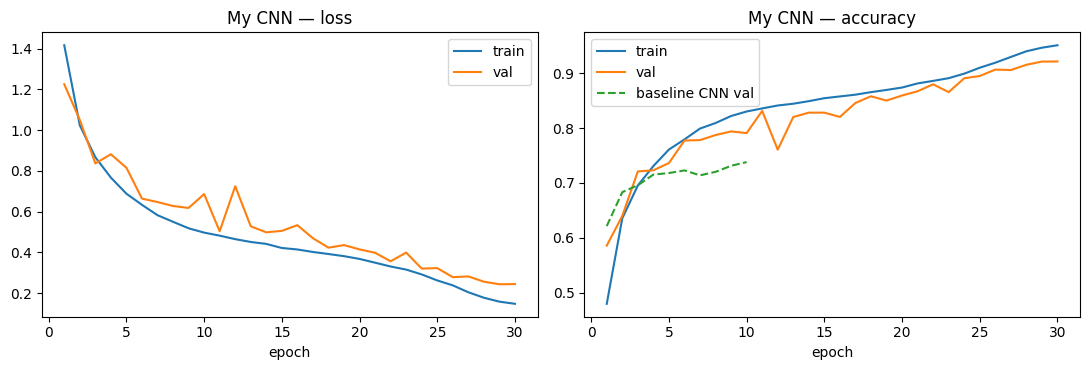

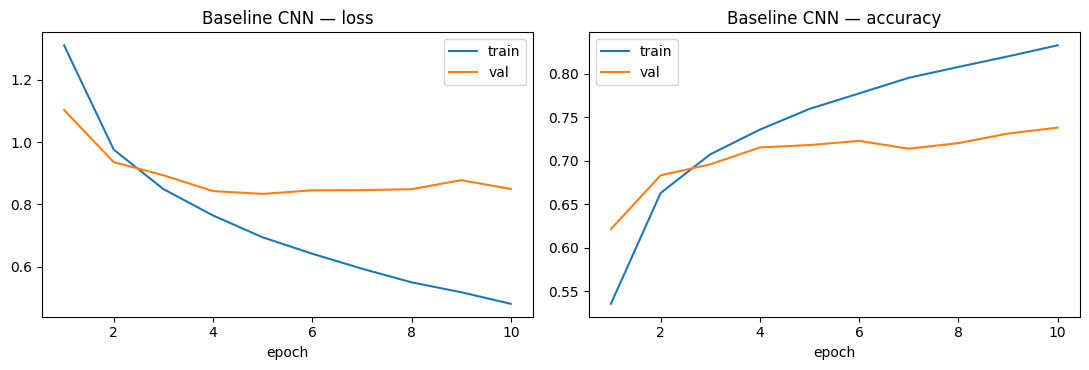

In [22]:
TRAIN_CFG = dict(bs=128, lr=0.1, optim="sgd", wd=5e-4, aug=True, onecycle=True)
my_model, h_my = fit(lambda: MyCNN(P_DROP), epochs=EPOCHS, **TRAIN_CFG)
print(f"my CNN val acc = {h_my['val_acc'][-1]:.4f}  vs  baseline CNN {h_base_cnn['val_acc'][-1]:.4f}"
      + (f"  (TA: {TA_BASELINE_VAL_ACC})" if TA_BASELINE_VAL_ACC else ""))
plot_curves(h_my, "My CNN", h_base_cnn)
plot_curves(h_base_cnn, "Baseline CNN")

## (c) Sensitivity study: dropout probability
Every other setting is kept fixed; each run uses 15 epochs to save time.
Training accuracy is measured **without** augmentation/dropout (eval mode) on 5,000 training images so it can be compared with validation accuracy.

{'dropout': 0.0, 'train acc': 0.9646, 'val acc': 0.9096, 'gap': 0.05500000000000005}
{'dropout': 0.1, 'train acc': 0.9612, 'val acc': 0.9068, 'gap': 0.054400000000000004}
{'dropout': 0.2, 'train acc': 0.9502, 'val acc': 0.903, 'gap': 0.04720000000000002}
{'dropout': 0.3, 'train acc': 0.9356, 'val acc': 0.8932, 'gap': 0.04239999999999999}
{'dropout': 0.5, 'train acc': 0.8968, 'val acc': 0.8658, 'gap': 0.031000000000000028}


,dropout,train acc,val acc,gap
0,0.000000,0.9646,0.9096,0.0550
1,0.100000,0.9612,0.9068,0.0544
2,0.200000,0.9502,0.9030,0.0472
3,0.300000,0.9356,0.8932,0.0424
4,0.500000,0.8968,0.8658,0.0310


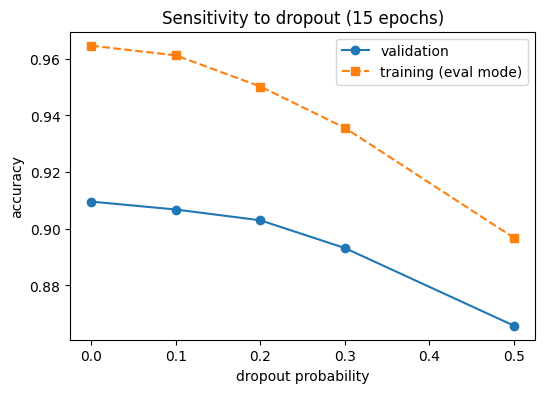

best dropout on validation: 0.0


In [23]:
drops = [0.0, 0.1, 0.2, 0.3, 0.5]
sens_rows = []
for p in drops:
    m, h = fit(lambda: MyCNN(p), epochs=15, verbose=False, **TRAIN_CFG)
    _, tr_acc = evaluate(m, X_tr[:5000], y_tr[:5000])
    sens_rows.append({"dropout": p, "train acc": tr_acc, "val acc": h["val_acc"][-1],
                      "gap": tr_acc - h["val_acc"][-1]})
    print(sens_rows[-1])
sens_df = pd.DataFrame(sens_rows)
display(sens_df.style.format({"train acc": "{:.4f}", "val acc": "{:.4f}", "gap": "{:.4f}"}))

plt.figure(figsize=(6, 4))
plt.plot(sens_df["dropout"], sens_df["val acc"], "o-", label="validation")
plt.plot(sens_df["dropout"], sens_df["train acc"], "s--", label="training (eval mode)")
plt.xlabel("dropout probability"); plt.ylabel("accuracy"); plt.legend()
plt.title("Sensitivity to dropout (15 epochs)"); plt.show()

best_p = float(sens_df.sort_values("val acc", ascending=False).iloc[0]["dropout"])
print("best dropout on validation:", best_p)

## (d) Final evaluation — test set used once
The final model uses the best dropout from (c). If it differs from the value used in (b), the model is retrained with the full 30-epoch schedule.

In [24]:
if best_p == P_DROP:
    final_model, h_final = my_model, h_my
else:
    final_model, h_final = fit(lambda: MyCNN(best_p), epochs=EPOCHS, verbose=False, **TRAIN_CFG)
final_val_acc = h_final["val_acc"][-1]

@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval()
    return torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)]).cpu().numpy()

test_preds = predict(final_model, X_te)            # the only pass over the test set
test_acc = float((test_preds == y_te.cpu().numpy()).mean())
print(f"final model (dropout={best_p}):  val acc {final_val_acc:.4f}   TEST acc {test_acc:.4f}")
print(f"val - test gap: {final_val_acc - test_acc:+.4f}")
if TA_BASELINE_TEST_ACC: print("TA baseline CNN test acc:", TA_BASELINE_TEST_ACC)
if PART2_TEST_ACC: print(f"Part II MLP test acc: {PART2_TEST_ACC:.4f}  ->  CNN gain {test_acc - PART2_TEST_ACC:+.4f}")

final model (dropout=0.0):  val acc 0.9192   TEST acc 0.9168
val - test gap: +0.0024
Part II MLP test acc: 0.5510  ->  CNN gain +0.3658


## Kaggle submission (validation set)
Validation predictions of the final CNN, matched to submission IDs with `validation_ids.csv` (see Part II).

In [25]:
val_preds = predict(final_model, X_va)
print(f"Part III validation accuracy: {(val_preds == y_va.cpu().numpy()).mean():.4f}")
build_submission(val_preds, os.path.join(OUT, "part3", "submission.csv"))

Part III validation accuracy: 0.9192
wrote ./part3/submission.csv: 5000 rows, columns ['id', 'label']
      id  label
0  45000      7
1  45001      1
2  45002      4
3  45003      1
4  45004      0


## Save tables, figures and results summary

In [26]:
import zipfile, shutil
g = globals()

def save_table(name, df):
    if df is not None:
        getattr(df, "data", df).to_csv(os.path.join(OUT, "tables", name), index=False)

save_table("partII_a_gradient_check.csv", g.get("grad_table"))
save_table("partII_b_hyperparameter_search.csv", g.get("res_df"))
if g.get("grad_df") is not None:
    g["grad_df"].to_csv(os.path.join(OUT, "tables", "partII_c_mean_abs_grad_per_layer.csv"))
if g.get("reg_rows"):
    save_table("partII_c_l2_strengths.csv", pd.DataFrame(g["reg_rows"]))
if g.get("MyCNN") is not None:
    save_table("partIII_b_layer_table.csv", layer_table(MyCNN().to(device)))
save_table("partIII_c_dropout_sensitivity.csv", g.get("sens_df"))

def last(h, k):
    return h[k][-1] if h and h.get(k) else None
summary = {
    "Part II  TA baseline val acc (our run)": last(g.get("h_base"), "val_acc"),
    "Part II  best config (hidden, lr, reg)": g.get("best_cfg"),
    "Part II  best model val acc": last(g.get("best_hist"), "val_acc"),
    "Part II  hinge-loss model val acc": last(g.get("h_hinge"), "val_acc"),
    "Part II  test acc (evaluated once)": g.get("part2_test_acc"),
    "Part III baseline CNN val acc (our run)": last(g.get("h_base_cnn"), "val_acc"),
    "Part III my CNN val acc": last(g.get("h_my"), "val_acc"),
    "Part III best dropout": g.get("best_p"),
    "Part III final model val acc": g.get("final_val_acc"),
    "Part III final model test acc (evaluated once)": g.get("test_acc"),
}
with open(os.path.join(OUT, "results_summary.txt"), "w") as f:
    for k, v in summary.items():
        f.write(f"{k}: {v}\n")
print(open(os.path.join(OUT, "results_summary.txt")).read())

zip_path = os.path.join(OUT, "A3_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write("nn_numpy.py", "nn_numpy.py")
    z.write(os.path.join(OUT, "results_summary.txt"), "results_summary.txt")
    for d in ["part2", "part3", "figures", "tables"]:
        for fn in sorted(os.listdir(os.path.join(OUT, d))):
            z.write(os.path.join(OUT, d, fn), f"{d}/{fn}")
print(zip_path)
for n in zipfile.ZipFile(zip_path).namelist():
    print("  ", n)

Part II  TA baseline val acc (our run): 0.2166
Part II  best config (hidden, lr, reg): (500, 0.05, 0.001)
Part II  best model val acc: 0.5546
Part II  hinge-loss model val acc: 0.5336
Part II  test acc (evaluated once): 0.551
Part III baseline CNN val acc (our run): 0.738
Part III my CNN val acc: 0.9212
Part III best dropout: 0.0
Part III final model val acc: 0.9192
Part III final model test acc (evaluated once): 0.9168

./A3_outputs.zip
   nn_numpy.py
   results_summary.txt
   part2/submission.csv
   part3/submission.csv
   figures/01_Overfitting_50_images.png
   figures/02_Best_model_500_0_05_0_001_loss.png
   figures/03_Accuracy.png
   figures/04_i_ReLU_different_initializations.png
   figures/05_training_accuracy_5k_subset.png
   figures/06_My_CNN_loss.png
   figures/07_Baseline_CNN_loss.png
   figures/08_Sensitivity_to_dropout_15_epochs.png
   tables/partIII_b_layer_table.csv
   tables/partIII_c_dropout_sensitivity.csv
   tables/partII_a_gradient_check.csv
   tables/partII_b_hyper

In [27]:
import os, json, zipfile, glob
from google.colab import _message, files

STUDENT_ID = "315511079"

# Save this notebook with all outputs
nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
nb_name = f"A3_{STUDENT_ID}.ipynb"
with open(nb_name, "w", encoding="utf-8") as f:
    json.dump(nb, f, ensure_ascii=False, indent=1)
n_out = sum(len(c.get("outputs", [])) for c in nb["cells"] if c["cell_type"] == "code")
print(f"notebook saved: {nb_name}  (code cells with outputs: {n_out})")

# e3 submission: notebook + nn_numpy.py
e3_zip = f"A3_{STUDENT_ID}.zip"
with zipfile.ZipFile(e3_zip, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(nb_name)
    z.write("nn_numpy.py")
print("e3 zip:", zipfile.ZipFile(e3_zip).namelist())

# Figures, tables and Kaggle files for the report
report_zip = "A3_report_materials.zip"
items = (["results_summary.txt", "part2/submission.csv", "part3/submission.csv"]
         + sorted(glob.glob("figures/*.png")) + sorted(glob.glob("tables/*.csv")))
with zipfile.ZipFile(report_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in items:
        if os.path.exists(p):
            z.write(p)
        else:
            print("missing:", p)
print(f"report materials: {len(glob.glob('figures/*.png'))} figures, "
      f"{len(glob.glob('tables/*.csv'))} tables")

files.download(e3_zip)
files.download(report_zip)

notebook saved: A3_315511079.ipynb  (code cells with outputs: 37)
e3 zip: ['A3_315511079.ipynb', 'nn_numpy.py']
report materials: 8 figures, 6 tables


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>